# 04 · Inference, OCR and CSV
**Notebook 4 of 6:** brief tasks 3.2 and 4. Run the detector on unseen test photos, crop the detected fields, preprocess them, read them with Tesseract, and save a CSV.

This notebook walks through **one test photo** stage by stage, exactly as the brief describes. It then runs the finished command-line tool on all 14 test photos:

```
python Custom_OCR.py --image <yourimage.jpg>
```

In [1]:
# --- 0. Paths: the same notebook runs in Google Colab (with Drive) or on a laptop ----------
import sys, os, subprocess, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules              # True when running inside Colab
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")                     # brief Task 1.1: mount Google Drive
    DRIVE = Path("/content/drive/MyDrive/Custom_OCR")  # datasets/, model/, results/ live here
    REPO = Path("/content/custom-ocr-lab-reports")     # the code (cloned from GitHub)
    if not REPO.exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/Subharshi1997/NextHikes-Project-9-MedicalReportReader.git", str(REPO)], check=True)
    subprocess.run("apt-get -qq install -y tesseract-ocr > /dev/null", shell=True)        # the OCR engine
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "-r", str(REPO / "requirements.txt")])
else:
    here = Path.cwd().resolve()
    REPO = here.parent if here.name == "notebooks" else here   # repo root on a local machine
    DRIVE = REPO                                               # locally, "Drive" = the repo folder

sys.path[:0] = [str(REPO), str(REPO / "tools")]   # so we can import Custom_OCR and the tools
import Custom_OCR; Custom_OCR.find_tesseract()      # finds Tesseract even when it is not on PATH (Windows)
DATASETS = DRIVE / "datasets"                     # brief folder structure: datasets/
RAW = DATASETS / "raw"                            # the 100 report photos (kept out of GitHub: they show a patient's name)
MODEL_DIR = DRIVE / "model"                       # brief: "a folder named model" for the weights
RESULTS = DRIVE / "results"                       # brief: results/
for p in (DATASETS, RAW, MODEL_DIR, RESULTS):
    p.mkdir(parents=True, exist_ok=True)
print("Code  :", REPO)
print("Data  :", DATASETS)
print("Colab :", IN_COLAB)

Code  : C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main
Data  : C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main\datasets
Colab : False


In [2]:
# --- 1. Libraries and the trained model ----------------------------------------------------
import json, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
import Custom_OCR as co, viz
from privacy import redact
viz.style()
OUT = RESULTS / "04_inference"; OUT.mkdir(parents=True, exist_ok=True)
weights = MODEL_DIR / "best.pt" if (MODEL_DIR / "best.pt").exists() else REPO / "model" / "best.pt"
model = co.load_model(weights)
ann = json.load(open(DATASETS / "annotations.json", encoding="utf-8"))
test_imgs = sorted(n for n, a in ann.items() if a["split"] == "test")
print("Test photos (never seen in training or tuning):", test_imgs)

Test photos (never seen in training or tuning): ['thyrocare_0_2177.jpg', 'thyrocare_0_2691.jpg', 'thyrocare_0_3333.jpg', 'thyrocare_0_3558.jpg', 'thyrocare_0_36.jpg', 'thyrocare_0_4046.jpg', 'thyrocare_0_4385.jpg', 'thyrocare_0_4979.jpg', 'thyrocare_0_5357.jpg', 'thyrocare_0_5640.jpg', 'thyrocare_0_5928.jpg', 'thyrocare_0_640.jpg', 'thyrocare_0_9108.jpg', 'thyrocare_0_9833.jpg']


## Stage 1 · Detect
YOLO returns a box, a class and a confidence for each field it finds.

12 fields detected: {'reference_range': 3, 'unit': 3, 'value': 3, 'test_name': 3}


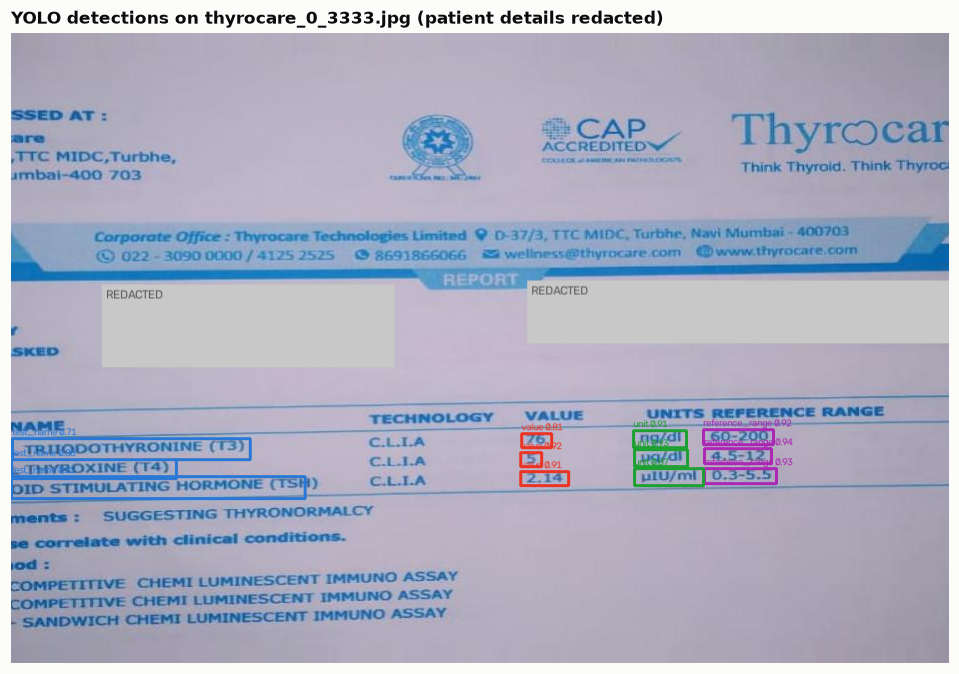

True

In [3]:
# --- 1.1 Detect on one test photo -------------------------------------------------------------
name = "thyrocare_0_3333.jpg"                       # a tilted, cropped thyroid photo
img = cv2.imread(str(RAW / name))
dets = co.detect(model, img, conf=0.25)
print(len(dets), "fields detected:", pd.Series([d["cls"] for d in dets]).value_counts().to_dict())
vis = co.draw(redact(img, ann[name]["redact"]), dets)
plt.figure(figsize=(11, 7.5)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title(f"YOLO detections on {name} (patient details redacted)"); plt.show()
cv2.imwrite(str(OUT / f"{Path(name).stem}_detections.jpg"), vis)

## Stage 2 · Crop and store in a list
The brief says: *"the coordinates of the detected objects are passed for cropping the detected objects and storing them in another list."* A small margin is kept around each crop, so a box drawn a little tight does not shave off the edge of a digit: 3 px in the brief recipe, 1 px in the tuned recipe (notebook 05 found that wider margins pull in fragments of neighbouring rows).

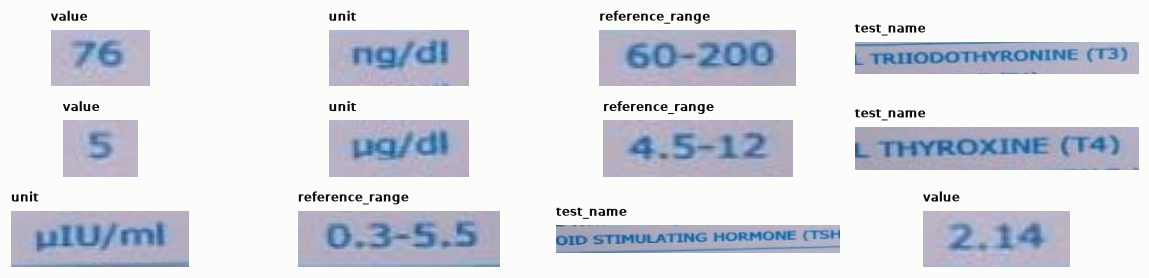

Crop sizes (h x w): [(21, 37), (24, 60), (22, 77), (28, 243), (21, 28), (24, 60)] ...


In [4]:
# --- 2.1 Crop every box into a list ---------------------------------------------------------
dets = sorted(dets, key=lambda d: (round(d["box"][1] / 12), d["box"][0]))    # reading order
crops = [co.crop(img, d["box"], pad=co.BRIEF.pad) for d in dets]          # brief recipe: 3 px margin
fig, axes = plt.subplots(3, 4, figsize=(11, 2.6))
for ax, d, c in zip(axes.ravel(), dets, crops):
    ax.imshow(cv2.cvtColor(c, cv2.COLOR_BGR2RGB)); ax.set_axis_off(); ax.set_title(d["cls"], fontsize=8)
plt.tight_layout(); plt.show()
print("Crop sizes (h x w):", [c.shape[:2] for c in crops[:6]], "...")

## Stage 3 · Preprocess (the brief's exact steps)
1. **Resize 3×**: Tesseract is trained on text roughly 20-30 px tall, and our fields are ~10 px.
2. **Grayscale**: colour carries no information about the characters.
3. **Gaussian blur**: smooths JPEG speckle that could be read as dots or commas.
4. **Otsu threshold, inverted**: white text on black. Otsu picks the cut-off automatically from the image's own histogram.
5. **`bitwise_not`**: flip back to black text on white, which is what Tesseract reads best.

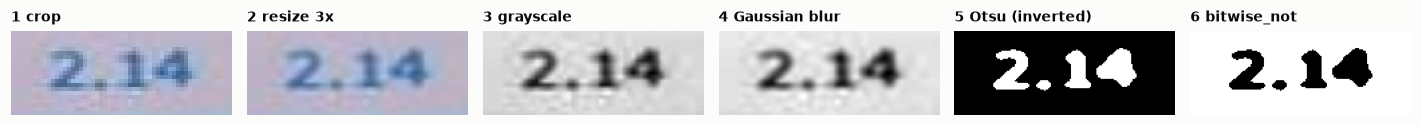

In [5]:
# --- 3.1 Show every intermediate image for one value crop -----------------------------------
k = next(i for i, d in enumerate(dets) if d["cls"] == "value" and d["box"][1] > dets[0]["box"][1] + 25)
steps = {}
_ = co.preprocess(crops[k], co.BRIEF, steps)
fig, axes = plt.subplots(1, 6, figsize=(13, 1.9))
titles = ["1 crop", "2 resize 3x", "3 grayscale", "4 Gaussian blur", "5 Otsu (inverted)", "6 bitwise_not"]
for ax, (key, im), t in zip(axes, steps.items(), titles):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap="gray"); ax.set_title(t, fontsize=9); ax.set_axis_off()
plt.tight_layout(); fig.savefig(OUT / "preprocessing_steps.png"); plt.show()

## Stage 4 · Read with Tesseract
We compare the brief's settings with the **tuned** settings. Notebook 05 chose the tuned settings by ablation on the training and validation photos only, so this test photo played no part in that choice.

In [6]:
# --- 4.1 Read each crop with both settings ----------------------------------------------------
line_px = np.median([c.shape[0] for c, d in zip(crops, dets) if d["cls"] == "value"])
rows = []
for d, c in zip(dets, crops):
    multi = co.is_multiline(c, line_px)
    c_tuned = co.crop(img, d["box"], pad=co.TUNED.pad)                     # each recipe uses its own margin
    t_brief, _ = co.tesseract_read(co.preprocess(c, co.BRIEF), d["cls"], multi, co.BRIEF)
    t_tuned, conf = co.tesseract_read(co.preprocess(c_tuned, co.TUNED), d["cls"], multi, co.TUNED)
    rows.append({"class": d["cls"], "yolo_conf": round(d["conf"], 2), "brief_text": t_brief,
                 "tuned_text": t_tuned, "tesseract_conf": round(conf)})
pd.DataFrame(rows)

,class,yolo_conf,brief_text,tuned_text,tesseract_conf
0,value,0.81,76,76,90
1,unit,0.91,ng/di,ng/dl,72
2,reference_range,0.92,60-200,60-200,95
3,test_name,0.71,1 TRIIODOTHYRONINE (T3),L TRIIODOTHYRONINE (T3),82
4,value,0.92,5,5,73
5,unit,0.93,pa/di,µg/dl,46
6,reference_range,0.94,4.5-12,4.5-12,87
7,test_name,0.88,L THYROXINE (T4),L THYROXINE (T4),87
8,unit,0.87,plu/mi,µIU/ml,45
9,reference_range,0.93,0.3-5.5,0.3-5.5,89


## Stage 5 · Rebuild the table rows
YOLO returns loose boxes, while a lab needs rows. A value belongs to the test name on the **same line**. A reference range belongs to the nearest test name **on or above it**, which also handles the vitamin page, where the range is printed under the name.

In [7]:
# --- 5.1 Full pipeline for this photo -> CSV ---------------------------------------------------
records, fields = co.read_fields(img, dets, co.TUNED, name)
table = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith("_")} for r in records])
table.to_csv(OUT / f"{Path(name).stem}.csv", index=False, encoding="utf-8-sig")
table

,image,row,test_name,value,unit,reference_range,det_conf_min,ocr_conf_min,needs_review,review_reason
0,thyrocare_0_3333.jpg,1,L TRIIODOTHYRONINE (T3),76,ng/dl,60-200,0.713,72.0,False,
1,thyrocare_0_3333.jpg,2,L THYROXINE (T4),5,µg/dl,4.5-12,0.879,46.0,True,low_ocr_conf
2,thyrocare_0_3333.jpg,3,OID STIMULATING HORMONE (TSt,2.14,µIU/ml,0.3-5.5,0.824,45.0,True,low_ocr_conf


**`needs_review`** is the safety net. A row is flagged when a field is missing, when the value does not parse as a number, or when YOLO or Tesseract is unsure. In production these rows go to a person, and the rest flow straight into the database.

## Stage 6 · The command-line tool on all test photos
`Custom_OCR.py` packages stages 1-5. Pointing it at a folder processes every image in it; this is the brief's *automation* step.

In [8]:
# --- 6.1 Run the CLI exactly as a user would -------------------------------------------------
import subprocess, sys, shutil
shutil.rmtree(OUT / "test_set", ignore_errors=True)       # no stale outputs from an older split
tdir = OUT / "test_images_input"; tdir.mkdir(exist_ok=True)
for n in test_imgs:
    shutil.copy(RAW / n, tdir / n)
cmd = [sys.executable, str(REPO / "Custom_OCR.py"), "--image", str(tdir), "--out", str(OUT / "test_set"),
       "--weights", str(weights)]
print(subprocess.run(cmd, capture_output=True, text=True).stdout)
shutil.rmtree(tdir)                              # the unredacted copies are not kept
for p in (OUT / "test_set" / "annotated").glob("*.jpg"):   # redact the saved annotated images
    n = p.name.replace("_boxes.jpg", ".jpg")
    cv2.imwrite(str(p), redact(cv2.imread(str(p)), ann[n]["redact"]))

thyrocare_0_2177.jpg: 3 tests extracted, 2 flagged for review
thyrocare_0_2691.jpg: 3 tests extracted, 2 flagged for review
thyrocare_0_3333.jpg: 3 tests extracted, 2 flagged for review
thyrocare_0_3558.jpg: 11 tests extracted, 9 flagged for review
thyrocare_0_36.jpg: 2 tests extracted, 1 flagged for review
thyrocare_0_4046.jpg: 2 tests extracted, 2 flagged for review
thyrocare_0_4385.jpg: 3 tests extracted, 3 flagged for review
thyrocare_0_4979.jpg: 11 tests extracted, 9 flagged for review
thyrocare_0_5357.jpg: 2 tests extracted, 2 flagged for review
thyrocare_0_5640.jpg: 11 tests extracted, 7 flagged for review
thyrocare_0_5928.jpg: 2 tests extracted, 2 flagged for review
thyrocare_0_640.jpg: 3 tests extracted, 3 flagged for review
thyrocare_0_9108.jpg: 3 tests extracted, 3 flagged for review
thyrocare_0_9833.jpg: 3 tests extracted, 3 flagged for review

CSV saved to C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main\results\04_inference\test_set



In [9]:
# --- 6.2 The combined CSV (one row per test, all test photos) -------------------------------
allcsv = pd.read_csv(OUT / "test_set" / "all_reports.csv", dtype={"value": str})   # keep values as text
print(len(allcsv), "rows |", int(allcsv.needs_review.sum()), "flagged for review")
allcsv.head(12)

62 rows | 50 flagged for review


,image,row,test_name,value,unit,reference_range,det_conf_min,ocr_conf_min,needs_review,review_reason
0,thyrocare_0_2177.jpg,1,TOTAL TRITODOTHYRONINE (T3),76,ng/dl,60-200,0.730,52.0,True,low_ocr_conf
1,thyrocare_0_2177.jpg,2,TOTAL THYROXINE (14),5,µg/dl,4.5-12,0.842,23.0,True,low_ocr_conf
2,thyrocare_0_2177.jpg,3,THYROID STIMULATING HORMONE (TSH),2.14,µIU/ml,0.3-5.5,0.817,78.0,False,NaN
3,thyrocare_0_2691.jpg,1,AL TRIIODOTHYRONINE (T3),76,ng/dl,60-200,0.753,47.0,True,low_ocr_conf
4,thyrocare_0_2691.jpg,2,AL THYROXINE (T4),5,µg/dl,4.5-12,0.829,58.0,True,low_ocr_conf
5,thyrocare_0_2691.jpg,3,ROID STIMULATING HORMONE (TSH),2.14,µIU/ml,0.3-5.5,0.838,81.0,False,NaN
6,thyrocare_0_3333.jpg,1,L TRIIODOTHYRONINE (T3),76,ng/dl,60-200,0.713,72.0,False,NaN
7,thyrocare_0_3333.jpg,2,L THYROXINE (T4),5,µg/dl,4.5-12,0.879,46.0,True,low_ocr_conf
8,thyrocare_0_3333.jpg,3,OID STIMULATING HORMONE (TSt,2.14,µIU/ml,0.3-5.5,0.824,45.0,True,low_ocr_conf
9,thyrocare_0_3558.jpg,1,ALKALINE PHOSPHATASE,67,U/l,45-129,0.739,49.0,True,low_ocr_conf


## Summary
- One command turns a photo, or a folder of photos, into a CSV with one row per test, confidence scores and a review flag.
- The brief's preprocessing is implemented exactly (`--mode brief`); the default `tuned` mode keeps the same steps with better-chosen settings.
- **How accurate is it?** That is notebook 05's job: we score every field against the hand-checked truth.

**Mentor check**
1. Why do we pad the crop by a few pixels before OCR?
2. Why does Tesseract prefer black text on a white background?
3. A value is read as "2.l4". Which part of the pipeline should catch that, and how?

**Next → Notebook 05:** evaluation and optimisation.